# Lecture Notes: Trigonometric Integrals
*Stewart, **Calculus**, §7.2*

**Learning objectives.** By the end of this lecture you should be able to:
1. Integrate $\sin^m x\cos^n x$ by saving one factor and substituting, or with half-angle identities.
2. Integrate $\tan^m x\sec^n x$ the same way.
3. Find $\int\tan x\,dx$, $\int\sec x\,dx$ and $\int\sec^3 x\,dx$.
4. Use product-to-sum identities for $\sin mx\cos nx$, $\sin mx\sin nx$ and $\cos mx\cos nx$.
5. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, u = sp.symbols("x u")

## 1. The identities we need

Every technique in this section uses one of these identities to rewrite the integrand.

| Name | Identity |
|---|---|
| Pythagorean | $\sin^2 x + \cos^2 x = 1$ |
| Pythagorean (tan/sec) | $\tan^2 x + 1 = \sec^2 x$ |
| Half-angle | $\sin^2 x = \tfrac12(1 - \cos 2x)$ |
| Half-angle | $\cos^2 x = \tfrac12(1 + \cos 2x)$ |
| Double-angle | $\sin x\cos x = \tfrac12\sin 2x$ |

We also need these derivatives, because they decide which substitution works:
$$\frac{d}{dx}\sin x = \cos x,\qquad \frac{d}{dx}\cos x = -\sin x,\qquad \frac{d}{dx}\tan x = \sec^2 x,\qquad \frac{d}{dx}\sec x = \sec x\tan x.$$

Let's confirm the identities with SymPy:

In [2]:
identities = {
    r"\sin^2 x + \cos^2 x = 1": sp.sin(x)**2 + sp.cos(x)**2 - 1,
    r"\tan^2 x + 1 = \sec^2 x": sp.tan(x)**2 + 1 - sp.sec(x)**2,
    r"\sin^2 x = \tfrac12(1-\cos 2x)": sp.sin(x)**2 - (1 - sp.cos(2 * x)) / 2,
    r"\cos^2 x = \tfrac12(1+\cos 2x)": sp.cos(x)**2 - (1 + sp.cos(2 * x)) / 2,
    r"\sin x\cos x = \tfrac12\sin 2x": sp.sin(x) * sp.cos(x) - sp.sin(2 * x) / 2,
}
for name, diff in identities.items():
    display(Math(name + rf"\quad\text{{: {sp.simplify(diff) == 0}}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### A checking function

As in §7.1, we check every antiderivative by differentiating it. Trig answers can look very different and still be equal, so if `simplify` cannot reduce $F' - f$ to $0$, the function also compares $F'$ and $f$ numerically at a few points.

In [3]:
def check(F, integrand, var=x):
    # Verify F' = integrand: symbolically first, then numerically at sample points
    diff = sp.diff(F, var) - integrand
    ok = sp.simplify(diff) == 0
    if not ok:
        pts = [0.3, 0.7, 1.1, 2.0, -0.4]
        ok = all(abs(complex(diff.subs(var, p).evalf())) < 1e-10 for p in pts)
    print("d/dx(answer) == integrand:", ok)
    return ok

## 2. Powers of sine and cosine: $\displaystyle\int\sin^m x\cos^n x\,dx$

### Example 1: $\displaystyle\int\cos^3 x\,dx$

The substitution $u = \cos x$ doesn't work, because $du = -\sin x\,dx$ and there is no $\sin x$ in the integrand. Instead, **save one factor** of $\cos x$ for $du$ and turn the rest into sines:
$$\cos^3 x = \cos^2 x\cdot\cos x = (1 - \sin^2 x)\cos x.$$
Now $u = \sin x$, $du = \cos x\,dx$:
$$\int\cos^3 x\,dx = \int(1 - u^2)\,du = u - \tfrac13u^3 + C = \sin x - \tfrac13\sin^3 x + C.$$

In [4]:
integrand_u = 1 - u**2
G = sp.integrate(integrand_u, u)
F = G.subs(u, sp.sin(x))
display(Math(r"\int(1-u^2)\,du = " + sp.latex(G) + r"\qquad\Longrightarrow\qquad \int\cos^3x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.cos(x)**3);

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Example 2: $\displaystyle\int\sin^5 x\cos^2 x\,dx$

This time the power of **sine** is odd. Save one $\sin x$ for $du$ and convert the remaining $\sin^4 x$ into cosines:
$$\sin^5 x\cos^2 x = (\sin^2 x)^2\cos^2 x\cdot\sin x = (1 - \cos^2 x)^2\cos^2 x\,\sin x.$$
With $u = \cos x$, $du = -\sin x\,dx$:
$$\begin{aligned}
\int\sin^5 x\cos^2 x\,dx &= -\int(1 - u^2)^2u^2\,du = -\int(u^2 - 2u^4 + u^6)\,du\\
&= -\tfrac13\cos^3 x + \tfrac25\cos^5 x - \tfrac17\cos^7 x + C.
\end{aligned}$$

In [5]:
integrand_u = -(1 - u**2)**2 * u**2
G = sp.integrate(sp.expand(integrand_u), u)
F = G.subs(u, sp.cos(x))
display(Math(r"\int\sin^5x\cos^2x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.sin(x)**5 * sp.cos(x)**2);

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### The strategy when one power is odd

| Case | Save | Convert the rest with | Substitute |
|---|---|---|---|
| power of $\cos$ is **odd** | one $\cos x$ | $\cos^2 x = 1 - \sin^2 x$ | $u = \sin x$ |
| power of $\sin$ is **odd** | one $\sin x$ | $\sin^2 x = 1 - \cos^2 x$ | $u = \cos x$ |

If both powers are odd, either choice works.

The function below does these steps for any $m, n \ge 0$ with at least one odd. It shows the integral in $u$, so you can compare it with your own work.

In [6]:
def sin_cos_odd(m, n):
    # ∫ sin^m x cos^n x dx when m or n is odd, by saving one factor and substituting
    if n % 2 == 1:                       # save cos x, u = sin x, du = cos x dx
        sub, g = sp.sin(x), u**m * (1 - u**2)**((n - 1) // 2)
    elif m % 2 == 1:                     # save sin x, u = cos x, du = -sin x dx
        sub, g = sp.cos(x), -(1 - u**2)**((m - 1) // 2) * u**n
    else:
        raise ValueError("both powers are even: use the half-angle identities")
    G = sp.integrate(sp.expand(g), u)
    F = G.subs(u, sub)
    display(Math(
        rf"u = {sp.latex(sub)}:\quad \int \sin^{{{m}}}x\cos^{{{n}}}x\,dx = \int {sp.latex(sp.factor(g))}\,du"
        rf" = {sp.latex(F)} + C"
    ))
    return F

F = sin_cos_odd(2, 5)
check(F, sp.sin(x)**2 * sp.cos(x)**5);
F = sin_cos_odd(3, 3)
check(F, sp.sin(x)**3 * sp.cos(x)**3);

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Example 3: $\displaystyle\int_0^\pi\sin^2 x\,dx$ (both powers even)

Saving one $\sin x$ leaves $\sin x$, which can't be written in terms of $\cos x$ without a square root. When **both powers are even**, use the half-angle identity instead:
$$\int_0^\pi\sin^2 x\,dx = \tfrac12\int_0^\pi(1 - \cos 2x)\,dx = \tfrac12\Big[x - \tfrac12\sin 2x\Big]_0^\pi = \tfrac12\Big(\pi - \tfrac12\sin 2\pi\Big) - \tfrac12(0 - 0) = \frac{\pi}{2}.$$

**Symbolic and numerical check:**

In [7]:
exact = sp.integrate(sp.sin(x)**2, (x, 0, sp.pi))
display(Math(r"\int_0^\pi\sin^2x\,dx = " + sp.latex(exact) + rf" \approx {float(exact):.10f}"))

xs = np.linspace(0, np.pi, 100_001)
print(f"NumPy trapezoid: {np.trapezoid(np.sin(xs)**2, xs):.10f}")

<IPython.core.display.Math object>

NumPy trapezoid: 1.5707963268


**Why $\pi/2$?** The half-angle identity says $\sin^2 x$ is the constant $\tfrac12$ plus a cosine wave $-\tfrac12\cos 2x$. Over a whole period the wave has zero net area, so only the $\tfrac12$ is left: $\tfrac12\cdot\pi$.

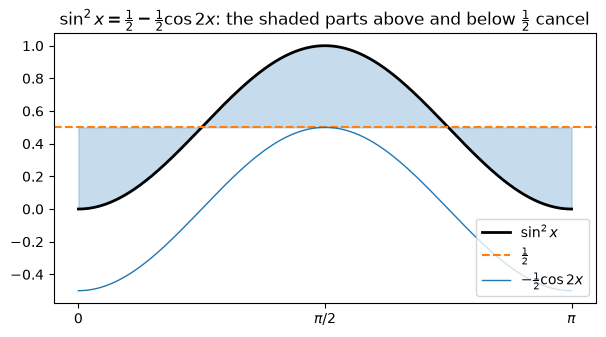

In [8]:
t = np.linspace(0, np.pi, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, np.sin(t)**2, "k", lw=2, label=r"$\sin^2 x$")
ax.axhline(0.5, color="C1", ls="--", label=r"$\frac{1}{2}$")
ax.plot(t, -0.5 * np.cos(2 * t), color="C0", lw=1, label=r"$-\frac{1}{2}\cos 2x$")
ax.fill_between(t, 0.5, np.sin(t)**2, alpha=0.25, color="C0")
ax.set_xticks([0, np.pi / 2, np.pi], ["0", r"$\pi/2$", r"$\pi$"])
ax.set_title(r"$\sin^2 x = \frac{1}{2} - \frac{1}{2}\cos 2x$: the shaded parts above and below $\frac{1}{2}$ cancel")
ax.legend(loc="lower right")
plt.show()

### Example 4: $\displaystyle\int\sin^4 x\,dx$

Use the half-angle identity, then use it **again** on $\cos^2 2x = \tfrac12(1 + \cos 4x)$:
$$\begin{aligned}
\int\sin^4 x\,dx &= \int\Big(\frac{1 - \cos 2x}{2}\Big)^2dx = \tfrac14\int(1 - 2\cos 2x + \cos^2 2x)\,dx\\
&= \tfrac14\int\Big(\tfrac32 - 2\cos 2x + \tfrac12\cos 4x\Big)dx\\
&= \tfrac38x - \tfrac14\sin 2x + \tfrac1{32}\sin 4x + C.
\end{aligned}$$

In §7.1 we got $\int\sin^4 x\,dx$ from the reduction formula. The answer looked different there, but the two antiderivatives have the same derivative:

In [9]:
F = sp.Rational(3, 8) * x - sp.sin(2 * x) / 4 + sp.sin(4 * x) / 32
display(Math(r"\int\sin^4x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.sin(x)**4)

# §7.1 reduction formula result: -1/4 cos x sin^3 x - 3/8 cos x sin x + 3/8 x
F_reduction = -sp.cos(x) * sp.sin(x)**3 / 4 - sp.Rational(3, 8) * sp.cos(x) * sp.sin(x) + sp.Rational(3, 8) * x
print("Half-angle answer - reduction answer =", sp.simplify(F - F_reduction))

<IPython.core.display.Math object>

d/dx(answer) == integrand: True
Half-angle answer - reduction answer = 0


### The strategy when both powers are even

Use the half-angle identities
$$\sin^2 x = \tfrac12(1 - \cos 2x),\qquad \cos^2 x = \tfrac12(1 + \cos 2x),$$
and sometimes $\sin x\cos x = \tfrac12\sin 2x$. Repeat as needed: each step halves the powers and doubles the angle.

For example, $\int\sin^2 x\cos^2 x\,dx = \int\big(\tfrac12\sin 2x\big)^2dx = \tfrac18\int(1 - \cos 4x)\,dx = \tfrac18x - \tfrac1{32}\sin 4x + C$:

In [10]:
F = x / 8 - sp.sin(4 * x) / 32
display(Math(r"\int\sin^2x\cos^2x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.sin(x)**2 * sp.cos(x)**2);

<IPython.core.display.Math object>

d/dx(answer) == integrand:

 True


## 3. Powers of tangent and secant: $\displaystyle\int\tan^m x\sec^n x\,dx$

The same idea works here, using the two derivatives
$$\frac{d}{dx}\tan x = \sec^2 x,\qquad \frac{d}{dx}\sec x = \sec x\tan x.$$

### Example 5: $\displaystyle\int\tan^6 x\sec^4 x\,dx$

Save $\sec^2 x$ for $du$ (with $u = \tan x$) and convert the remaining $\sec^2 x$ with $\sec^2 x = 1 + \tan^2 x$:
$$\int\tan^6 x\sec^4 x\,dx = \int\tan^6 x\,(1 + \tan^2 x)\sec^2 x\,dx = \int u^6(1 + u^2)\,du = \frac{\tan^7 x}{7} + \frac{\tan^9 x}{9} + C.$$

In [11]:
G = sp.integrate(sp.expand(u**6 * (1 + u**2)), u)
F = G.subs(u, sp.tan(x))
display(Math(r"\int\tan^6x\sec^4x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.tan(x)**6 * sp.sec(x)**4);

<IPython.core.display.Math object>

d/dx(answer) == integrand:

 True


### Example 6: $\displaystyle\int\tan^5\theta\sec^7\theta\,d\theta$

Now the power of secant is odd, so we can't save $\sec^2\theta$ and still convert the rest. The power of **tangent** is odd, so save $\sec\theta\tan\theta$ for $du$ (with $u = \sec\theta$) and convert the remaining $\tan^4\theta$ with $\tan^2\theta = \sec^2\theta - 1$:
$$\begin{aligned}
\int\tan^5\theta\sec^7\theta\,d\theta &= \int(\sec^2\theta - 1)^2\sec^6\theta\cdot\sec\theta\tan\theta\,d\theta = \int(u^2 - 1)^2u^6\,du\\
&= \frac{\sec^{11}\theta}{11} - \frac{2\sec^9\theta}{9} + \frac{\sec^7\theta}{7} + C.
\end{aligned}$$

In [12]:
G = sp.integrate(sp.expand((u**2 - 1)**2 * u**6), u)
F = G.subs(u, sp.sec(x))
display(Math(r"\int\tan^5\theta\sec^7\theta\,d\theta = " + sp.latex(F.subs(x, sp.Symbol("theta"))) + " + C"))
check(F, sp.tan(x)**5 * sp.sec(x)**7);

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### The strategy for $\tan^m x\sec^n x$

| Case | Save | Convert the rest with | Substitute |
|---|---|---|---|
| power of $\sec$ is **even** ($n \ge 2$) | $\sec^2 x$ | $\sec^2 x = 1 + \tan^2 x$ | $u = \tan x$ |
| power of $\tan$ is **odd** | $\sec x\tan x$ | $\tan^2 x = \sec^2 x - 1$ | $u = \sec x$ |

The same rules work for $\cot^m x\csc^n x$, using $\frac{d}{dx}\cot x = -\csc^2 x$, $\frac{d}{dx}\csc x = -\csc x\cot x$ and $1 + \cot^2 x = \csc^2 x$.

In [13]:
def tan_sec(m, n):
    # ∫ tan^m x sec^n x dx when sec power is even (n >= 2) or tan power is odd
    if n % 2 == 0 and n >= 2:            # save sec^2 x, u = tan x
        sub, g = sp.tan(x), u**m * (1 + u**2)**((n - 2) // 2)
    elif m % 2 == 1 and n >= 1:          # save sec x tan x, u = sec x
        sub, g = sp.sec(x), (u**2 - 1)**((m - 1) // 2) * u**(n - 1)
    else:
        raise ValueError("no direct substitution: use identities and/or integration by parts")
    G = sp.integrate(sp.expand(g), u)
    F = G.subs(u, sub)
    display(Math(
        rf"u = {sp.latex(sub)}:\quad \int \tan^{{{m}}}x\sec^{{{n}}}x\,dx = \int {sp.latex(sp.factor(g))}\,du"
        rf" = {sp.latex(F)} + C"
    ))
    return F

F = tan_sec(2, 4)
check(F, sp.tan(x)**2 * sp.sec(x)**4);
F = tan_sec(3, 3)
check(F, sp.tan(x)**3 * sp.sec(x)**3);

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### The other cases: $\int\tan x\,dx$ and $\int\sec x\,dx$

If the power of tangent is even and the power of secant is odd, neither rule applies. We need two basic integrals.

**Tangent.** Write $\tan x = \dfrac{\sin x}{\cos x}$ and substitute $u = \cos x$:
$$\int\tan x\,dx = -\int\frac{du}{u} = -\ln|\cos x| + C = \ln|\sec x| + C.$$

**Secant.** Multiply top and bottom by $\sec x + \tan x$. The new numerator is the derivative of the denominator:
$$\int\sec x\,dx = \int\frac{\sec^2 x + \sec x\tan x}{\sec x + \tan x}\,dx = \ln|\sec x + \tan x| + C.$$

(In the code we drop the absolute values. That doesn't change the derivative.)

In [14]:
F_tan = sp.log(sp.sec(x))
F_sec = sp.log(sp.sec(x) + sp.tan(x))
display(Math(r"\int\tan x\,dx = " + sp.latex(F_tan) + " + C"))
check(F_tan, sp.tan(x))
display(Math(r"\int\sec x\,dx = " + sp.latex(F_sec) + " + C"))
check(F_sec, sp.sec(x));

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Example 7: $\displaystyle\int\tan^3 x\,dx$

The power of tangent is odd, but there is no $\sec x$ to save. Instead, convert $\tan^2 x = \sec^2 x - 1$ and split:
$$\int\tan^3 x\,dx = \int\tan x\,(\sec^2 x - 1)\,dx = \int\tan x\sec^2 x\,dx - \int\tan x\,dx = \frac{\tan^2 x}{2} - \ln|\sec x| + C.$$
The first integral uses $u = \tan x$.

In [15]:
F = sp.tan(x)**2 / 2 - sp.log(sp.sec(x))
display(Math(r"\int\tan^3x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.tan(x)**3);

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Example 8: $\displaystyle\int\sec^3 x\,dx$ (integration by parts)

Odd powers of secant alone need integration by parts. This is the cyclic case from §7.1. Take
$$u = \sec x,\quad dv = \sec^2 x\,dx\quad\Longrightarrow\quad du = \sec x\tan x\,dx,\quad v = \tan x.$$
Then, with $\tan^2 x = \sec^2 x - 1$:
$$\begin{aligned}
\int\sec^3 x\,dx &= \sec x\tan x - \int\sec x\tan^2 x\,dx\\
&= \sec x\tan x - \int\sec^3 x\,dx + \int\sec x\,dx.
\end{aligned}$$
$\int\sec^3 x\,dx$ appears on both sides. Solve for it:
$$\boxed{\int\sec^3 x\,dx = \tfrac12\big(\sec x\tan x + \ln|\sec x + \tan x|\big) + C}$$

**In SymPy**, treat $I = \int\sec^3 x\,dx$ as an unknown, as in §7.1:

In [16]:
I = sp.Symbol("I")
equation = sp.Eq(I, sp.sec(x) * sp.tan(x) - I + F_sec)
display(equation)
F = sp.solve(equation, I)[0]
display(Math(r"\int\sec^3x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.sec(x)**3);

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


## 4. Products with different angles

Integrals like $\int\sin 4x\cos 5x\,dx$ show up in Fourier series. Use the **product-to-sum** identities:
$$\begin{aligned}
\sin A\cos B &= \tfrac12\big[\sin(A - B) + \sin(A + B)\big]\\
\sin A\sin B &= \tfrac12\big[\cos(A - B) - \cos(A + B)\big]\\
\cos A\cos B &= \tfrac12\big[\cos(A - B) + \cos(A + B)\big]
\end{aligned}$$
Each one comes from adding or subtracting the addition formulas for $\sin(A \pm B)$ or $\cos(A \pm B)$.

In [17]:
A, B = sp.symbols("A B")
product_to_sum = [
    (sp.sin(A) * sp.cos(B), (sp.sin(A - B) + sp.sin(A + B)) / 2),
    (sp.sin(A) * sp.sin(B), (sp.cos(A - B) - sp.cos(A + B)) / 2),
    (sp.cos(A) * sp.cos(B), (sp.cos(A - B) + sp.cos(A + B)) / 2),
]
for lhs, rhs in product_to_sum:
    ok = sp.simplify(sp.expand_trig(lhs - rhs)) == 0
    display(Math(sp.latex(lhs) + " = " + sp.latex(rhs) + rf"\quad\text{{: {ok}}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Example 9: $\displaystyle\int\sin 4x\cos 5x\,dx$

With $A = 4x$, $B = 5x$:
$$\sin 4x\cos 5x = \tfrac12\big[\sin(-x) + \sin 9x\big] = \tfrac12(-\sin x + \sin 9x),$$
so
$$\int\sin 4x\cos 5x\,dx = \tfrac12\Big(\cos x - \tfrac19\cos 9x\Big) + C.$$

In [18]:
F = (sp.cos(x) - sp.cos(9 * x) / 9) / 2
display(Math(r"\int\sin 4x\cos 5x\,dx = " + sp.latex(F) + " + C"))
check(F, sp.sin(4 * x) * sp.cos(5 * x));

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Application: orthogonality

For positive integers $m$ and $n$, the product-to-sum identities give
$$\int_{-\pi}^{\pi}\sin mx\sin nx\,dx = \begin{cases}0 & m \ne n\\ \pi & m = n\end{cases}$$
When $m \ne n$, both $\cos(m - n)x$ and $\cos(m + n)x$ go through whole periods on $[-\pi, \pi]$, so their integrals are $0$. When $m = n$, $\cos(m - n)x = 1$ contributes $\tfrac12\cdot 2\pi = \pi$.

This fact is the basis of Fourier series. Here is the table of values for $m, n = 1, \dots, 5$, computed both ways:

In [19]:
N = 5
exact = sp.Matrix(N, N, lambda i, j: sp.integrate(sp.sin((i + 1) * x) * sp.sin((j + 1) * x), (x, -sp.pi, sp.pi)))
display(Math(r"\left[\int_{-\pi}^{\pi}\sin mx\sin nx\,dx\right]_{m,n=1}^{5} = " + sp.latex(exact)))

xs = np.linspace(-np.pi, np.pi, 20_001)
numeric = np.array([[np.trapezoid(np.sin(m * xs) * np.sin(k * xs), xs) for k in range(1, N + 1)] for m in range(1, N + 1)])
print("NumPy trapezoid (divided by π):")
print(np.round(numeric / np.pi, 8) + 0.0)  # + 0.0 turns -0. into 0.

<IPython.core.display.Math object>

NumPy trapezoid (divided by π):
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


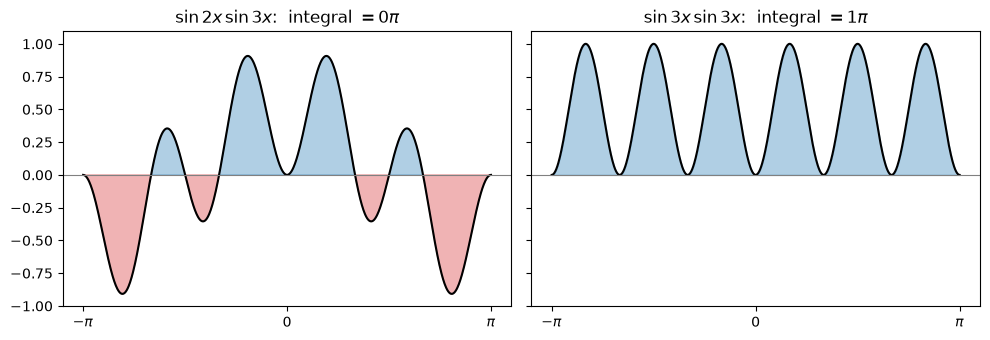

In [20]:
t = np.linspace(-np.pi, np.pi, 800)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (m, k) in zip(axes, [(2, 3), (3, 3)]):
    y = np.sin(m * t) * np.sin(k * t)
    ax.plot(t, y, "k", lw=1.5)
    ax.fill_between(t, 0, y, where=y > 0, alpha=0.35, color="C0")
    ax.fill_between(t, 0, y, where=y < 0, alpha=0.35, color="C3")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xticks([-np.pi, 0, np.pi], [r"$-\pi$", "0", r"$\pi$"])
    ax.set_title(rf"$\sin {m}x\,\sin {k}x$:  integral $= {np.trapezoid(y, t) / np.pi:.0f}\pi$")
plt.tight_layout()
plt.show()

## 5. Common mistakes

1. **Saving the wrong factor.** To substitute $u = \sin x$ you must save a $\cos x$, and the other way around. With $u = \tan x$ save $\sec^2 x$; with $u = \sec x$ save $\sec x\tan x$.
2. **Using $u = \sin x$ when the power of $\cos x$ is even.** The leftover $\cos x$ becomes $\sqrt{1 - u^2}$. Use the half-angle identities instead.
3. **Sign errors with $u = \cos x$:** $du = -\sin x\,dx$.
4. **Half-angle identities:** the angle doubles. $\int\cos^2 3x\,dx = \tfrac12\int(1 + \cos 6x)\,dx$, not $\cos 3x$ or $\cos 2x$.
5. **Forgetting the absolute values** in $\ln|\sec x|$ and $\ln|\sec x + \tan x|$.
6. **Different-looking answers.** Trig antiderivatives can differ by a constant, such as $\tfrac12\sin^2 x$ and $-\tfrac12\cos^2 x$ for $\int\sin x\cos x\,dx$. Differentiate to compare them.

In [21]:
F1, F2 = sp.sin(x)**2 / 2, -sp.cos(x)**2 / 2
check(F1, sp.sin(x) * sp.cos(x))
check(F2, sp.sin(x) * sp.cos(x))
print("F1 - F2 =", sp.simplify(F1 - F2))

d/dx(answer) == integrand: True
d/dx(answer) == integrand: True
F1 - F2 = 1/2


## 6. Practice problems

Try each by hand first, then run the cell below to check your answers. SymPy may give an answer that looks different from yours, so differentiate yours and compare.

1. $\displaystyle\int\sin^3 x\cos^2 x\,dx$
2. $\displaystyle\int\cos^4 x\,dx$
3. $\displaystyle\int\tan^2 x\sec^4 x\,dx$
4. $\displaystyle\int\tan^3 x\sec x\,dx$
5. $\displaystyle\int\cos 3x\cos 7x\,dx$
6. $\displaystyle\int_0^{\pi/2}\sin^2 x\cos^2 x\,dx$
7. $\displaystyle\int_0^{\pi/4}\sec^4 x\,dx$

In [22]:
problems = [
    sp.sin(x)**3 * sp.cos(x)**2,
    sp.cos(x)**4,
    sp.tan(x)**2 * sp.sec(x)**4,
    sp.tan(x)**3 * sp.sec(x),
    sp.cos(3 * x) * sp.cos(7 * x),
]
for p in problems:
    F = sp.simplify(sp.integrate(p, x))
    display(Math(r"\int " + sp.latex(p) + r"\,dx = " + sp.latex(F) + " + C"))

definite = [
    (sp.sin(x)**2 * sp.cos(x)**2, 0, sp.pi / 2, lambda t: np.sin(t)**2 * np.cos(t)**2),
    (sp.sec(x)**4, 0, sp.pi / 4, lambda t: 1 / np.cos(t)**4),
]
for p, a, b, fn in definite:
    val = sp.integrate(p, (x, a, b))
    xs = np.linspace(float(a), float(b), 100_001)
    display(Math(rf"\int_{{{sp.latex(a)}}}^{{{sp.latex(b)}}} " + sp.latex(p) + r"\,dx = "
                 + sp.latex(sp.simplify(val)) + rf" \approx {float(val):.6f}"))
    print(f"NumPy check: {np.trapezoid(fn(xs), xs):.6f}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

NumPy check: 0.196350


<IPython.core.display.Math object>

NumPy check: 1.333333


## Summary

| Integrand | Strategy | Substitution |
|---|---|---|
| $\sin^m x\cos^n x$, $n$ odd | Save $\cos x$, use $\cos^2 x = 1 - \sin^2 x$ | $u = \sin x$ |
| $\sin^m x\cos^n x$, $m$ odd | Save $\sin x$, use $\sin^2 x = 1 - \cos^2 x$ | $u = \cos x$ |
| $\sin^m x\cos^n x$, both even | Half-angle identities, repeated | none |
| $\tan^m x\sec^n x$, $n$ even | Save $\sec^2 x$, use $\sec^2 x = 1 + \tan^2 x$ | $u = \tan x$ |
| $\tan^m x\sec^n x$, $m$ odd | Save $\sec x\tan x$, use $\tan^2 x = \sec^2 x - 1$ | $u = \sec x$ |
| $\tan^m x$ alone, odd $\sec^n x$ | $\tan^2 x = \sec^2 x - 1$; parts for $\sec^3 x$ | varies |
| $\sin mx\cos nx$, etc. | Product-to-sum identities | none |

$$\int\tan x\,dx = \ln|\sec x| + C,\qquad \int\sec x\,dx = \ln|\sec x + \tan x| + C$$